# TA-EVRP Results Analysis

Loads the aggregated CSVs from `results/` and visualizes performance across planners, TRSP agents, and networks.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 11,
})

RESULTS_DIR = Path('../results')

df = pd.read_csv(RESULTS_DIR / 'ta_evrp_results.csv')
meta_net = pd.read_csv(RESULTS_DIR / 'networks.csv')
meta_prob = pd.read_csv(RESULTS_DIR / 'problem_instances.csv')
meta_traffic = pd.read_csv(RESULTS_DIR / 'traffic.csv')

# Friendly display names
planner_order = ['MILP', 'Heuristic', 'mTSP']
agent_order   = ['SSP', 'SARSA']
planner_colors = {'MILP': '#4C72B0', 'Heuristic': '#DD8452', 'mTSP': '#55A868'}
agent_markers  = {'SSP': 'o', 'SARSA': 's'}

print(f"{len(df)} rows loaded")
df.head()

19 rows loaded


,evrp_planner,trsp_agent,problem,network,traffic,uav_bms,makespan_s,ugv_distance_m,uav_distance_m,total_distance_m,ugv_energy_kwh,uav_energy_kwh,total_energy_kwh,recharges,throughput_tasks_per_h,gap_pct,run_id
0,Heuristic,SARSA,P1,N2,T1,No,517.0,23662.40,0.0,23662.40,NaN,0.0,NaN,0,69.63,NaN,heuristic_sarsa_20260529_155453
1,Heuristic,SARSA,P1,N3,T1,No,955.0,34401.34,0.0,34401.34,NaN,0.0,NaN,0,37.70,NaN,heuristic_sarsa_20260529_155912
2,Heuristic,SSP,P1,N1,T1,No,466.0,11904.74,0.0,11904.74,NaN,0.0,NaN,0,77.25,NaN,heuristic_dijkstra_20260529_155216
3,Heuristic,SSP,P1,N2,T1,No,567.0,23662.40,0.0,23662.40,NaN,0.0,NaN,0,63.49,NaN,heuristic_dijkstra_20260529_155432
4,Heuristic,SSP,P1,N3,T1,No,994.0,34401.34,0.0,34401.34,NaN,0.0,NaN,0,36.22,NaN,heuristic_dijkstra_20260529_155901


## Summary statistics

In [2]:
summary = (
    df.groupby(['evrp_planner', 'trsp_agent', 'network'])
    [['makespan_s', 'total_distance_m', 'throughput_tasks_per_h', 'recharges']]
    .agg(['mean', 'min', 'max', 'count'])
)
summary

makespan_s                        \
                                      mean     min     max count   
evrp_planner trsp_agent network                                    
Heuristic    SARSA      N2           517.0   517.0   517.0     1   
                        N3           955.0   955.0   955.0     1   
             SSP        N1           466.0   466.0   466.0     1   
                        N2           567.0   567.0   567.0     1   
                        N3           994.0   994.0   994.0     1   
MILP         SARSA      N2          1311.0  1311.0  1311.0     1   
                        N3          1869.0  1714.0  2024.0     2   
             SSP        N1           725.0   725.0   725.0     1   
                        N2          1361.0  1361.0  1361.0     1   
                        N3          1945.0  1807.0  2083.0     2   
mTSP         SARSA      N2           518.0   518.0   518.0     1   
                        N3          1284.0  1063.0  1505.0     2   
             SSP        N1           342.0   342.0   342.0     1   
                        N2           619.0   619.0   619.0     1   
                        N3          1307.0  1086.0  1528.0     2   

                                total_distance_m                            \
                                            mean       min       max count   
evrp_planner trsp_agent network                                              
Heuristic    SARSA      N2             23662.400  23662.40  23662.40     1   
                        N3             34401.340  34401.34  34401.34     1   
             SSP        N1             11904.740  11904.74  11904.74     1   
                        N2             23662.400  23662.40  23662.40     1   
                        N3             34401.340  34401.34  34401.34     1   
MILP         SARSA      N2             17748.800  17748.80  17748.80     1   
                        N3             33516.960  29864.10  37169.82     2   
             SSP        N1             10959.390  10959.39  10959.39     1   
                        N2             17748.800  17748.80  17748.80     1   
                        N3             33516.960  29864.10  37169.82     2   
mTSP         SARSA      N2             23662.400  23662.40  23662.40     1   
                        N3             40682.085  38416.71  42947.46     2   
             SSP        N1             14164.870  14164.87  14164.87     1   
                        N2             23662.400  23662.40  23662.40     1   
                        N3             40682.085  38416.71  42947.46     2   

                                throughput_tasks_per_h                        \
                                                  mean     min     max count   
evrp_planner trsp_agent network                                                
Heuristic    SARSA      N2                      69.630   69.63   69.63     1   
                        N3                      37.700   37.70   37.70     1   
             SSP        N1                      77.250   77.25   77.25     1   
                        N2                      63.490   63.49   63.49     1   
                        N3                      36.220   36.22   36.22     1   
MILP         SARSA      N2                      27.460   27.46   27.46     1   
                        N3                      19.395   17.79   21.00     2   
             SSP        N1                      49.660   49.66   49.66     1   
                        N2                      26.450   26.45   26.45     1   
                        N3                      18.600   17.28   19.92     2   
mTSP         SARSA      N2                      69.500   69.50   69.50     1   
                        N3                      28.895   23.92   33.87     2   
             SSP        N1                     105.260  105.26  105.26     1   
                        N2                      58.160   58.16   58.16     1   
                        N3                

## Planner comparison by network

Grouped bar charts for the four key metrics: makespan, total distance, throughput, and recharge stops. Each group is a network; bars are planners; line style distinguishes TRSP agent.

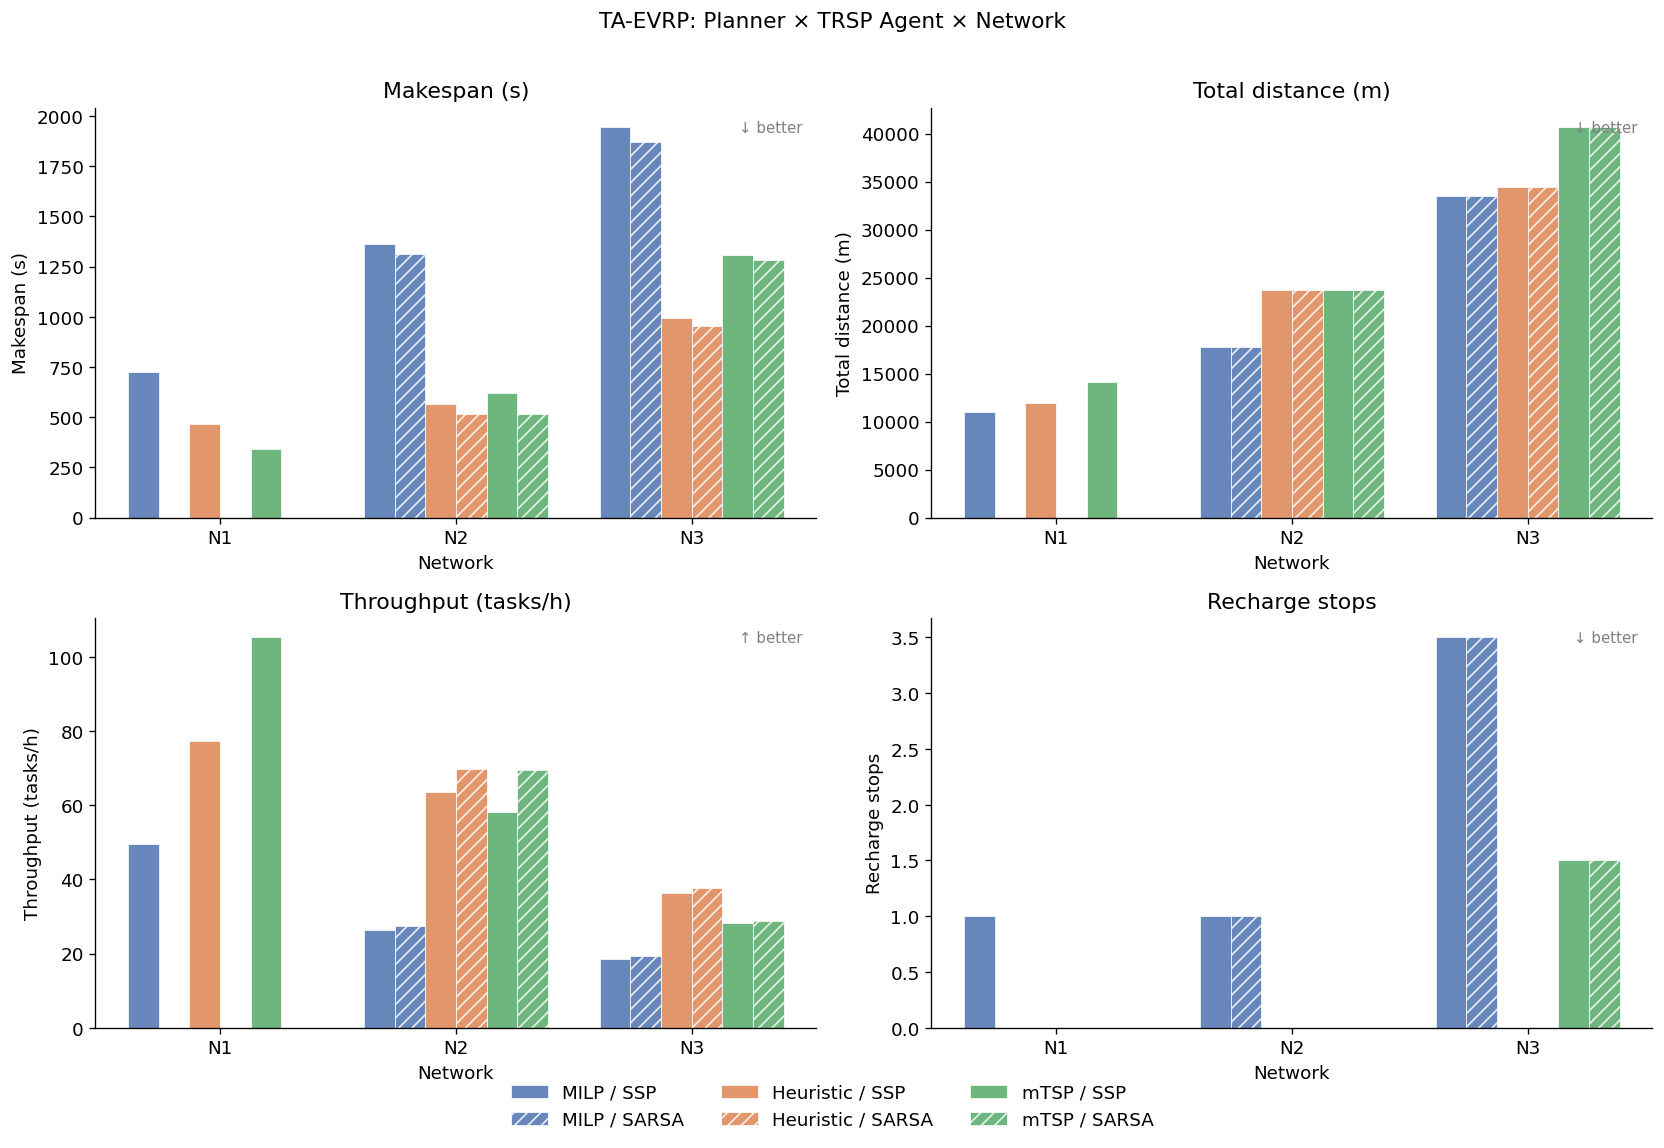

In [3]:
metrics = {
    'makespan_s':            ('Makespan (s)',           False),
    'total_distance_m':      ('Total distance (m)',     False),
    'throughput_tasks_per_h':('Throughput (tasks/h)',   True),
    'recharges':             ('Recharge stops',         False),
}

networks = sorted(df['network'].unique())
combos = [(p, a) for p in planner_order for a in agent_order]
x = np.arange(len(networks))
width = 0.13
offsets = np.linspace(-(len(combos)-1)/2*width, (len(combos)-1)/2*width, len(combos))

hatches = {'SSP': '', 'SARSA': '///'}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('TA-EVRP: Planner × TRSP Agent × Network', fontsize=13, y=1.01)

for ax, (metric, (ylabel, higher_better)) in zip(axes.flat, metrics.items()):
    for offset, (planner, agent) in zip(offsets, combos):
        vals = []
        for net in networks:
            sub = df[(df['evrp_planner'] == planner) & (df['trsp_agent'] == agent) & (df['network'] == net)]
            vals.append(sub[metric].mean() if len(sub) else np.nan)
        ax.bar(
            x + offset, vals, width,
            color=planner_colors[planner],
            hatch=hatches[agent],
            alpha=0.85,
            label=f'{planner} / {agent}',
            edgecolor='white',
            linewidth=0.5,
        )
    ax.set_xticks(x)
    ax.set_xticklabels(networks)
    ax.set_xlabel('Network')
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    arrow = '↑ better' if higher_better else '↓ better'
    ax.text(0.98, 0.97, arrow, transform=ax.transAxes, ha='right', va='top',
            fontsize=9, color='gray')

# Deduplicated legend
handles, labels = axes.flat[0].get_legend_handles_labels()
seen = {}
for h, l in zip(handles, labels):
    seen.setdefault(l, h)
fig.legend(seen.values(), seen.keys(), loc='lower center', ncol=len(combos)//2,
           bbox_to_anchor=(0.5, -0.04), frameon=False)

fig.tight_layout()
plt.show()

## SARSA vs SSP: relative improvement

Percent change in makespan and throughput when using SARSA instead of SSP, for each (planner, network) combination. Positive = SARSA wins.

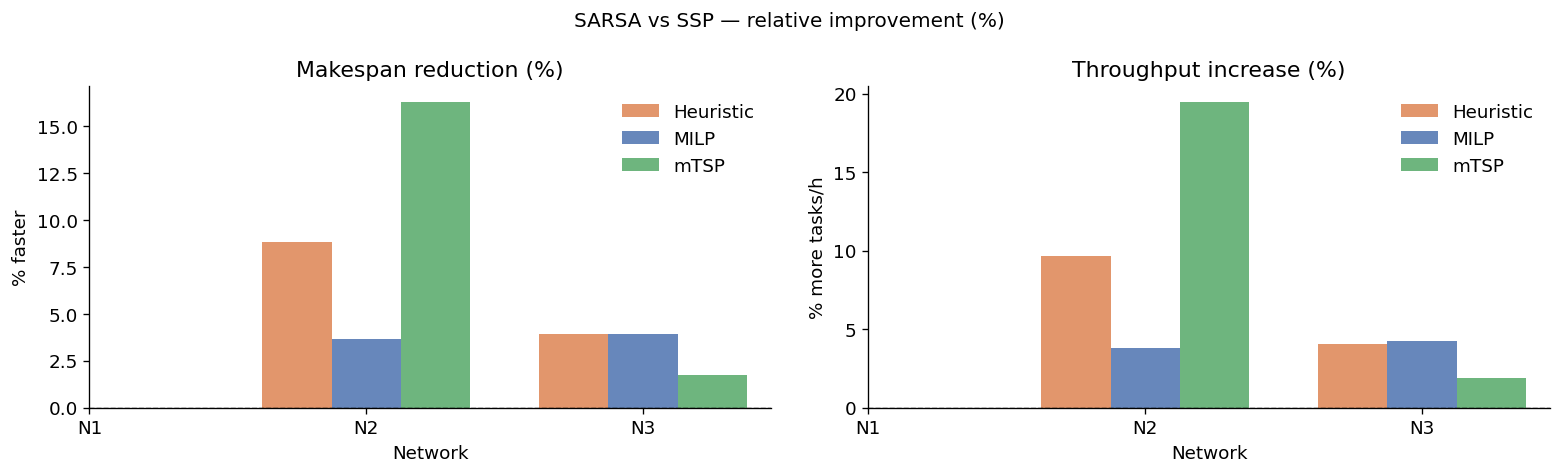

In [4]:
pivot_makespan = df.groupby(['evrp_planner', 'trsp_agent', 'network'])['makespan_s'].mean().unstack('trsp_agent')
pivot_throughput = df.groupby(['evrp_planner', 'trsp_agent', 'network'])['throughput_tasks_per_h'].mean().unstack('trsp_agent')

# pct improvement: negative makespan delta is good; positive throughput delta is good
delta_makespan   = (pivot_makespan['SSP']   - pivot_makespan['SARSA'])   / pivot_makespan['SSP']   * 100
delta_throughput = (pivot_throughput['SARSA'] - pivot_throughput['SSP']) / pivot_throughput['SSP'] * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('SARSA vs SSP — relative improvement (%)', fontsize=12)

for ax, (delta, title, unit) in zip(axes, [
    (delta_makespan,   'Makespan reduction (%)',    '% faster'),
    (delta_throughput, 'Throughput increase (%)',   '% more tasks/h'),
]):
    delta_df = delta.reset_index()
    delta_df.columns = ['evrp_planner', 'network', 'delta']
    planners = sorted(delta_df['evrp_planner'].unique())
    nets     = sorted(delta_df['network'].unique())
    x2 = np.arange(len(nets))
    w2 = 0.25
    for i, pl in enumerate(planners):
        sub = delta_df[delta_df['evrp_planner'] == pl]
        vals2 = [sub[sub['network'] == n]['delta'].values[0]
                 if len(sub[sub['network'] == n]) else np.nan
                 for n in nets]
        ax.bar(x2 + (i - 1) * w2, vals2, w2, label=pl, color=planner_colors[pl], alpha=0.85)
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set_xticks(x2)
    ax.set_xticklabels(nets)
    ax.set_xlabel('Network')
    ax.set_ylabel(unit)
    ax.set_title(title)
    ax.legend(frameon=False)

fig.tight_layout()
plt.show()

## Makespan vs. distance scatter

Each point is one run. Color = planner, marker = TRSP agent. Shows whether lower distance routes actually lead to lower makespan (they should, modulo traffic).

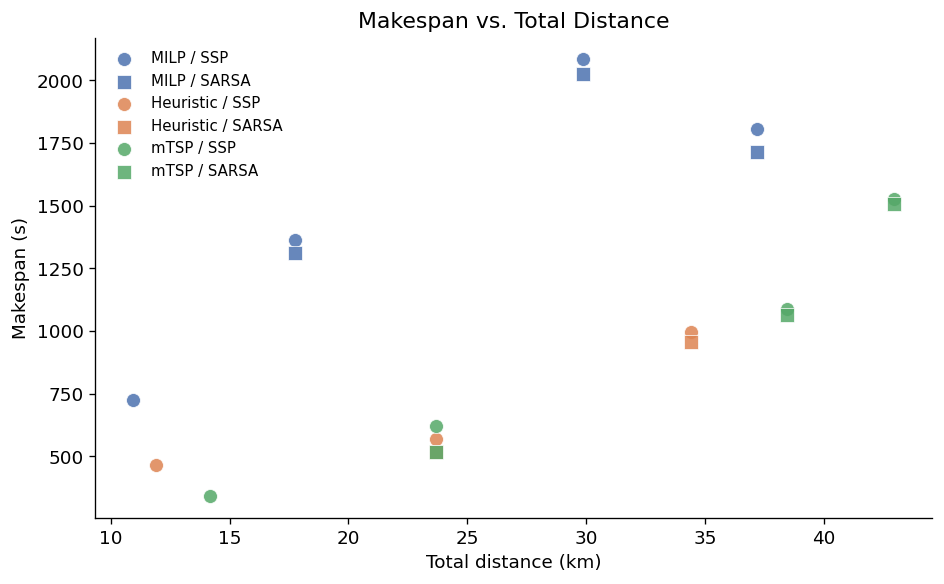

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))

for planner in planner_order:
    for agent in agent_order:
        sub = df[(df['evrp_planner'] == planner) & (df['trsp_agent'] == agent)]
        if sub.empty:
            continue
        ax.scatter(
            sub['total_distance_m'] / 1000,
            sub['makespan_s'],
            color=planner_colors[planner],
            marker=agent_markers[agent],
            s=70, alpha=0.85,
            label=f'{planner} / {agent}',
            edgecolors='white', linewidths=0.5,
        )

ax.set_xlabel('Total distance (km)')
ax.set_ylabel('Makespan (s)')
ax.set_title('Makespan vs. Total Distance')
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## Throughput heatmap

Mean throughput (tasks/h) for each (planner, network) cell, split by TRSP agent.

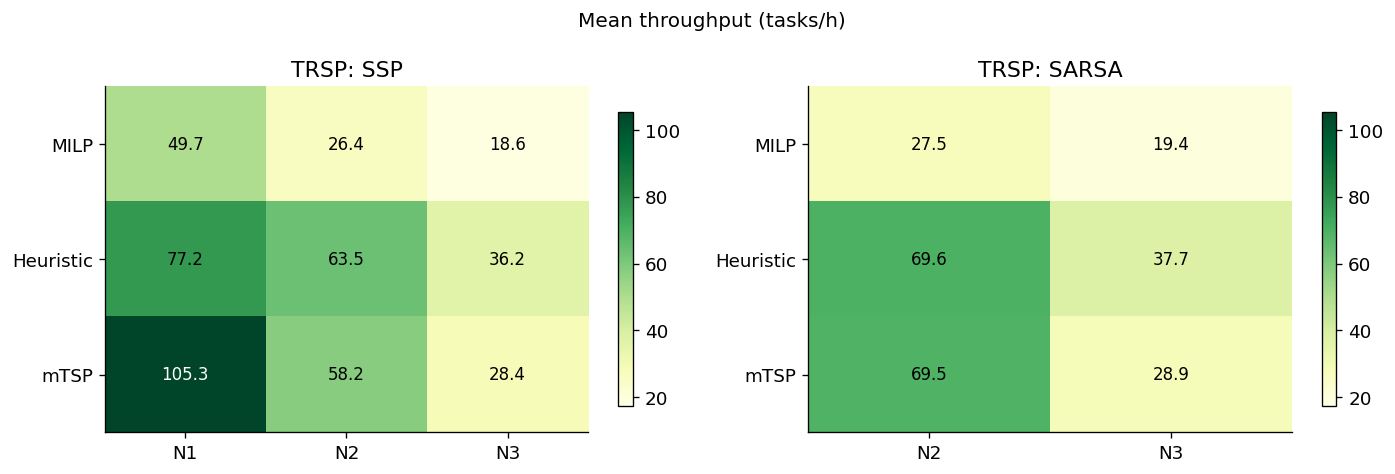

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Mean throughput (tasks/h)', fontsize=12)

vmin = df['throughput_tasks_per_h'].min()
vmax = df['throughput_tasks_per_h'].max()

for ax, agent in zip(axes, agent_order):
    pivot = (
        df[df['trsp_agent'] == agent]
        .groupby(['evrp_planner', 'network'])['throughput_tasks_per_h']
        .mean()
        .unstack('network')
        .reindex(planner_order)
    )
    im = ax.imshow(pivot.values, aspect='auto', cmap='YlGn', vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index)
    ax.set_title(f'TRSP: {agent}')
    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            val = pivot.values[i, j]
            if not np.isnan(val):
                ax.text(j, i, f'{val:.1f}', ha='center', va='center', fontsize=10,
                        color='black' if val < (vmin + vmax) / 2 * 1.3 else 'white')
    plt.colorbar(im, ax=ax, shrink=0.85)

fig.tight_layout()
plt.show()